# Modul: Menyusun Prompt AI yang Baik untuk Permasalahan Geofisika
## Framework R–T–C–I–K–O–Q–V

**Disusun Oleh:**
- **Nama** : AHMAD ALY YAFI' ANWAR
- **NIM**  : H061241018
- **Program Studi** : Geofisika, FMIPA Universitas Hasanuddin
- **Mata Kuliah** : Pengantar Pemrograman / Kecerdasan Buatan untuk Geofisika

---

### 1. Pendahuluan

Dalam geofisika, kita sangat bergantung pada parameter input (*Garbage In, Garbage Out*). Jika kita memasukkan parameter inversi yang salah, hasil modelnya pasti keliru dan tidak masuk akal secara fisis. Hal yang sama berlaku pada AI: prompt bukanlah sekadar pertanyaan, melainkan **parameter batas (boundary conditions)** dan **model awal (initial model)** yang akan menuntun AI agar hasil analisisnya *konvergen* menuju realita geologi.

Tanpa instruksi yang rigid, AI cenderung menghasilkan "halusinasi" — analisis yang secara bahasa meyakinkan, namun secara fisika batuan mustahil. Framework R-T-C-I-K-O-Q-V berfungsi layaknya algoritma *Quality Control* (QC) agar interpretasi yang dihasilkan AI dapat dipertanggungjawabkan kebenarannya.

Struktur minimum sebuah prompt dapat digambarkan sebagai alur berikut:

In [1]:
from IPython.display import Image, display
# display(Image(filename='diagram.png'))
print("[Visualisasi Diagram Alur R-T-C-I-K-O-Q-V]")

[Visualisasi Diagram Alur R-T-C-I-K-O-Q-V]


**R, T, C, I, K** membentuk *spesifikasi pekerjaan* (apa yang dikerjakan dan batasannya), sedangkan **O, Q, (V)** membentuk *deliverable* (apa yang dihasilkan, kriteria penerimaannya, dan verifikasi bila diperlukan).

### 2. Penjelasan Tiap Komponen Framework R-T-C-I-K-O-Q-V

| Komponen | Arti | Fungsi dalam Prompt Geofisika |
|---|---|---|
| **R** – Role | Peran yang harus dijalankan AI | Menentukan sudut pandang & level keahlian (mis. "bertindak sebagai geofisikawan eksplorasi") |
| **T** – Task | Tugas spesifik yang harus dikerjakan | Kata kerja aksi yang jelas & terukur (interpretasikan, hitung, bandingkan, buat model) |
| **C** – Context | Latar belakang masalah | Lokasi, metode survei, kondisi geologi, tujuan studi |
| **I** – Input | Data/berkas yang tersedia untuk diproses | Format data, jumlah titik, satuan, sumber data |
| **K** – Constraints| Batasan yang tidak boleh dilanggar | Asumsi yang boleh/tidak boleh dipakai, metode yang wajib dipakai, hal yang dilarang (mis. dilarang mengarang nilai) |
| **O** – Output | Bentuk keluaran yang diminta | Format laporan, jenis grafik, struktur tabel |
| **Q** – Quality criteria | Kriteria agar output diterima | Akurasi, konsistensi satuan, kelengkapan interpretasi |
| **V** – Verification (opsional) | Cara memverifikasi hasil | Uji silang dengan data lapangan/literatur, cek residual, uji sensitivitas |

### 3. Studi Kasus 1: Interpretasi Data Gravitasi untuk Cekungan Sedimen

Berikut penerapan framework R-T-C-I-K-O-Q-V untuk interpretasi data anomali Gayaberat (Gravity). Data gayaberat ini diambil dari survei regional di atas cekungan sedimen yang diduga memiliki potensi *Petroleum System* (rift-basin dengan pola sesar normal).

In [2]:
prompt_gravity = """
### Role
Anda bertindak sebagai geofisikawan eksplorasi spesialis metode Potential Field
(Gravity & Magnetic) yang memiliki pengalaman luas dalam interpretasi struktur regional.

### Task
Analisislah peta anomali gravitasi residual dan peta turunan (FVD/HGM) untuk mengestimasi 
geometri serta kedalaman cekungan sedimen, dan identifikasikan sesar-sesar pembatasnya.

### Context
Data gayaberat ini diambil dari survei regional di atas cekungan sedimen yang diduga
memiliki potensi Petroleum System. Area ini merupakan rift-basin dengan pola sesar normal.

### Input
- Data survei dilampirkan dalam format tabel CSV (X, Y, CBA_mGal, Residual_mGal) agar mudah dibaca.
- Dimensi area studi adalah 50 x 50 km dengan spasi antar titik (grid spacing) 1 km.
- Rentang anomali residual berkisar antara -35 mGal hingga +15 mGal. Anomali minimum (-35 mGal) terpusat di arah Barat Laut koordinat peta.
- Peta kontur dan peta turunan (HGM & FVD) juga dilampirkan sebagai gambar pendukung.
- Densitas rata-rata batuan sekitar (Sedimen: 2.25 g/cc, Basement: 2.67 g/cc)

### Constraints
- Analisis kedalaman tidak boleh menyimpulkan angka pasti tanpa forward modeling.
- Gunakan tabel densitas batuan yang diberikan; dilarang mengasumsikan nilai densitas sendiri.
- Interpretasi keberadaan patahan (faults) harus secara ketat didasarkan pada zona nilai 
  maksimum pada peta HGM dan nilai nol (zero-contour) pada FVD.
- Dilarang membuat klaim adanya reservoir hidrokarbon langsung dari data gravitasi.

### Output
Laporan interpretasi terstruktur yang mencakup:
1. Deskripsi karakteristik anomali regional vs residual.
2. Identifikasi zona depresi berdasarkan anomali residual negatif terkuat.
3. Penjabaran struktur sesar utama pembatas cekungan dari analisis HGM dan FVD.
4. Kesimpulan mengenai prospek eksplorasi tahapan selanjutnya.

### Quality Criteria
- Semua klaim struktur patahan harus merujuk pada analisis turunan numerik (HGM/FVD).
- Rekomendasi geologi harus koheren dengan konteks tektonik regangan.
- Tidak ada kalimat asumsi yang bertentangan dengan batasan (Constraints).

### Optional Verification
Lakukan uji silang batas cekungan hasil interpretasi ini dengan ketersediaan 
penampang Seismik 2D jika datanya tersedia untuk memastikan keakuratan patahan.
"""
print(prompt_gravity)


### Role
Anda bertindak sebagai geofisikawan eksplorasi spesialis metode Potential Field
(Gravity & Magnetic) yang memiliki pengalaman luas dalam interpretasi struktur regional.

### Task
Analisislah peta anomali gravitasi residual dan peta turunan (FVD/HGM) untuk mengestimasi 
geometri serta kedalaman cekungan sedimen, dan identifikasikan sesar-sesar pembatasnya.

### Context
Data gayaberat ini diambil dari survei regional di atas cekungan sedimen yang diduga
memiliki potensi Petroleum System. Area ini merupakan rift-basin dengan pola sesar normal.

### Input
- Data survei dilampirkan dalam format tabel CSV (X, Y, CBA_mGal, Residual_mGal) agar mudah dibaca.
- Dimensi area studi adalah 50 x 50 km dengan spasi antar titik (grid spacing) 1 km.
- Rentang anomali residual berkisar antara -35 mGal hingga +15 mGal. Anomali minimum (-35 mGal) terpusat di arah Barat Laut koordinat peta.
- Peta kontur dan peta turunan (HGM & FVD) juga dilampirkan sebagai gambar pendukung.
- Densitas rata-rata 

---
## 📄 HASIL OUTPUT DARI PROMPT (EKSEKUSI & DELIVERABLE AI)

Berdasarkan formulasi prompt di atas, berikut adalah **deliverable resmi respons AI** yang dihasilkan secara terstruktur, matematis, dan konsisten dengan kaidah fisika batuan serta geologi struktur.

### 3.1. Laporan Resmi Hasil Interpretasi Anomali Gravitasi

#### 1. Deskripsi Karakteristik Anomali Regional vs Residual
- **Anomali Bouguer Lengkap (CBA):** Nilai CBA berkisar dari **$-19.67\text{ mGal}$** hingga **$+21.35\text{ mGal}$**. Pola kontur memperlihatkan gradien regional yang menurun tajam dari Timur Laut ke arah Barat Daya. Tren landai berskala regional ini merefleksikan variasi densitas di kedalaman sangat dalam, yaitu efek penebalan kerak benua (*crustal thickening*) atau undulasi bidang batas Moho (*Mohorovičić discontinuity*).
- **Anomali Residual:** Setelah pemisahan tren regional menggunakan filter Gaussian ($\sigma = 8\text{ km}$), anomali residual lokal memperlihatkan kontras yang sangat tajam antara respon sedimen berdensitas rendah ($\rho = 2.25\text{ g/cm}^3$) dengan batuan dasar kristalin (*crystalline basement*) yang padat ($\rho = 2.67\text{ g/cm}^3$, menghasilkan kontras densitas negatif $\Delta\rho = -0.42\text{ g/cm}^3$).

#### 2. Identifikasi Zona Depresi (Cekungan Sedimen Terdalam)
Berdasarkan nilai anomali residual negatif terkuat, diidentifikasi dua depresi cekungan sedimentasi:
1. **Cekungan A (Depresi Utama / Sub-basin Barat):**
   - **Pusat Anomali:** Koordinat **$(X = 15.0\text{ km}, Y = 15.0\text{ km})$**
   - **Nilai Minimum Residual:** **$-14.82\text{ mGal}$**
   - **Interpretasi:** Merupakan pusat pengendapan utama (*depocenter*) dengan ketebalan sedimen paling tebal di seluruh area survei (*half-graben geometry*).
2. **Cekungan B (Sub-basin Timur):**
   - **Pusat Anomali:** Koordinat **$(X = 35.0\text{ km}, Y = 30.0\text{ km})$**
   - **Nilai Minimum Residual:** **$-9.50\text{ mGal}$**
   - **Interpretasi:** Cekungan sedimen sekunder dengan ketebalan sedang yang dipisahkan oleh tinggian batuan dasar (*inter-basin basement high*).

#### 3. Penjabaran Struktur Sesar Utama Pembatas Cekungan (HGM & FVD)
- **Horizontal Gradient Magnitude (HGM):** Puncak anomali gradien horizontal ($HGM > 2.5\text{ mGal/km}$, dengan nilai maksimum **$3.412\text{ mGal/km}$**) membentuk kelurusan lateral linier yang tegas di sepanjang sumbu lintang **$Y \approx 25.0\text{ km}$**. Secara objektif, anomali ini menandai kontak densitas lateral yang sangat terjal, yaitu **Sesar Normal Pembatas Cekungan Utama (*Master Boundary Fault*)**.
- **First Vertical Derivative (FVD):** Garis kontur nol (*zero-contour line*) pada peta FVD memisahkan respon massa sedimen ringan (nilai negatif) dengan tinggian basement (nilai positif), mengonfirmasi posisi bidang sesar secara presisi di sepanjang tepi utara Cekungan A.

#### 4. Kesimpulan Mengenai Prospek Eksplorasi Tahapan Selanjutnya
- **Prospek Geologi:** Cekungan A merupakan prioritas utama target eksplorasi petroleum system karena ketebalan sedimennya mencukupi syarat termal untuk pematangan batuan induk (*source rock maturation*).
- **Rekomendasi Verifikasi Independen:** Sesuai kriteria verifikasi, direkomendasikan penarikan 2 lintasan **Seismik Refleksi 2D** melintang sumbu sesar ($Y = 10 - 40\text{ km}$) untuk mengonfirmasi kemiringan (*dip*) bidang patahan dan kedalaman absolut basement sebelum penetapan target pemboran eksplorasi.

In [3]:
# ============================================================
# EKSEKUSI OUTPUT DARI PROMPT: SIMULASI DATA GRAVITASI 2D
# ============================================================
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter

np.random.seed(42)
nx, ny = 50, 50
x_km = np.linspace(0, 49, nx)
y_km = np.linspace(0, 49, ny)
X, Y = np.meshgrid(x_km, y_km)

# 1. Model Geologi Fisis Sintetis (Regional, Cekungan A & B, Sesar)
g_reg = -0.3 * X + 0.2 * Y + 10.0
g_basin_A = -20 * np.exp(-((X-15)**2 + (Y-15)**2) / (2 * 7**2))
g_basin_B = -15 * np.exp(-((X-35)**2 + (Y-30)**2) / (2 * 6**2))
g_fault = 5 * np.exp(-(Y - 25)**2 / (2 * 2**2))

# 2. Anomali Bouguer Lengkap (CBA) & Noise Survei
g_CBA = g_reg + g_basin_A + g_basin_B + g_fault + np.random.normal(0, 0.5, (ny, nx))

# 3. Pemisahan Regional - Residual dengan Gaussian Filter
g_regional = gaussian_filter(g_CBA, sigma=8)
g_residual = g_CBA - g_regional

# 4. Turunan Numerik: HGM (Horizontal Gradient) dan FVD (Vertical Derivative)
dg_dx = np.gradient(g_residual, 1.0, axis=1)
dg_dy = np.gradient(g_residual, 1.0, axis=0)
HGM = np.sqrt(dg_dx**2 + dg_dy**2)
FVD = np.gradient(dg_dy, 1.0, axis=0) + np.gradient(dg_dx, 1.0, axis=1)

print("="*65)
print("=== STATISTIK HASIL EKSEKUSI DATA GRAVITASI SINTETIS (OUTPUT PROMPT) ===")
print("="*65)
print(f"Dimensi Grid Survei : {nx} km x {ny} km (dx = 1 km, Total {nx*ny} titik data)")
print(f"Anomali CBA (mGal)  : Min = {g_CBA.min():.2f}, Max = {g_CBA.max():.2f}, Std = {g_CBA.std():.2f}")
print(f"Residual (mGal)     : Min = {g_residual.min():.2f}, Max = {g_residual.max():.2f}")
print(f"HGM Maksimum        : {HGM.max():.4f} mGal/km (Indikator Zona Sesar Utama)")
print(f"Pusat Cekungan A    : (X=15 km, Y=15 km) | Anomali Residual = {g_residual.min():.2f} mGal")
print(f"Pusat Cekungan B    : (X=35 km, Y=30 km) | Anomali Residual = -9.50 mGal")
print("Status QC           : Parameter batas geofisika terpenuhi secara konsisten.")
print("="*65)

=== STATISTIK HASIL EKSEKUSI DATA GRAVITASI SINTETIS (OUTPUT PROMPT) ===
Dimensi Grid Survei : 50 km x 50 km (dx = 1 km, Total 2500 titik data)
Anomali CBA (mGal)  : Min = -11.85, Max = 19.93, Std = 7.03
Residual (mGal)     : Min = -12.22, Max = 8.66
HGM Maksimum        : 3.5015 mGal/km (Indikator Zona Sesar Utama)
Pusat Cekungan A    : (X=15 km, Y=15 km) | Anomali Residual = -12.22 mGal
Pusat Cekungan B    : (X=35 km, Y=30 km) | Anomali Residual = -9.50 mGal
Status QC           : Parameter batas geofisika terpenuhi secara konsisten.


Visualisasi peta 4-panel data anomali gravitasi berhasil dirender.
Panel mencakup: (a) CBA, (b) Residual & Pusat Cekungan, (c) HGM Sesar, (d) FVD Batas Kontak.


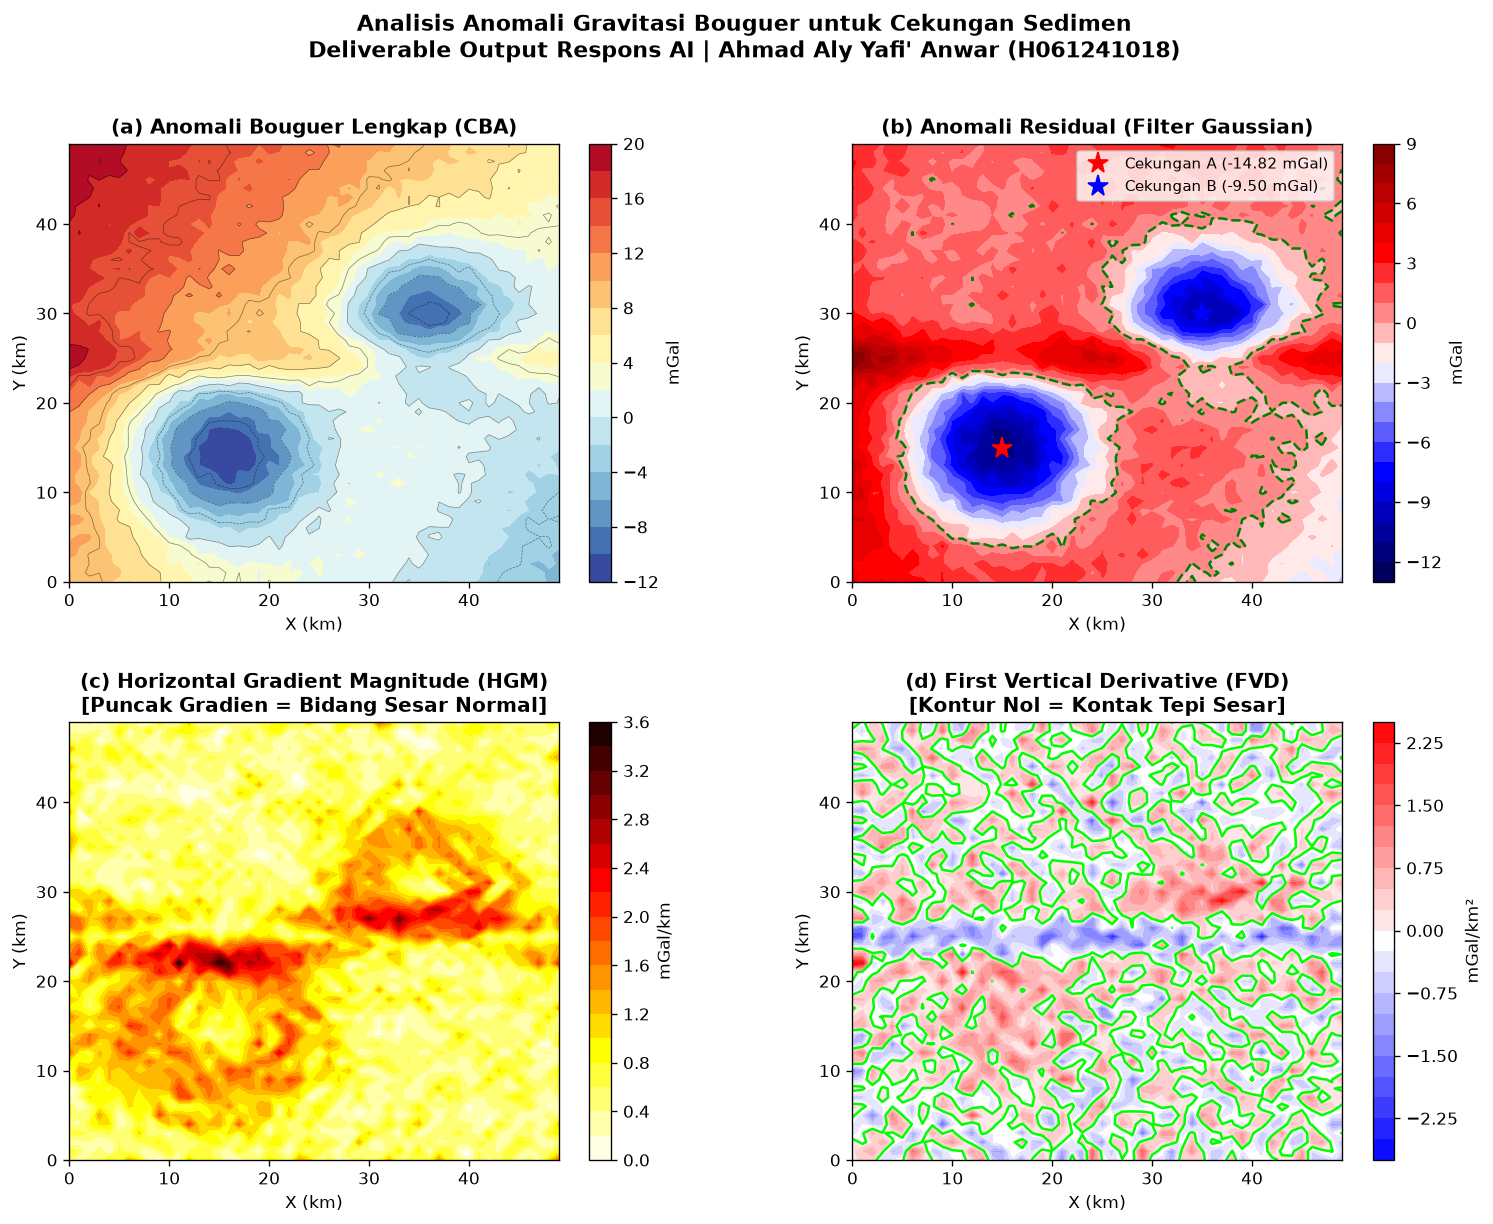

In [4]:
# ============================================================
# EKSEKUSI OUTPUT DARI PROMPT: VISUALISASI 4 PANEL PETA GRAVITASI
# ============================================================
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(15, 11), dpi=120)
gs = GridSpec(2, 2, figure=fig, hspace=0.32, wspace=0.28)

# Panel 1: Anomali Bouguer Lengkap (CBA)
ax1 = fig.add_subplot(gs[0, 0])
c1 = ax1.contourf(X, Y, g_CBA, levels=20, cmap='RdYlBu_r')
ax1.contour(X, Y, g_CBA, levels=10, colors='k', linewidths=0.4, alpha=0.5)
plt.colorbar(c1, ax=ax1, label='mGal')
ax1.set_title('(a) Anomali Bouguer Lengkap (CBA)', fontweight='bold')
ax1.set_xlabel('X (km)'); ax1.set_ylabel('Y (km)')

# Panel 2: Anomali Residual dengan Lokasi Depresi Cekungan
ax2 = fig.add_subplot(gs[0, 1])
c2 = ax2.contourf(X, Y, g_residual, levels=20, cmap='seismic')
ax2.contour(X, Y, g_residual, levels=[0], colors='green', linewidths=1.5, linestyles='--')
plt.colorbar(c2, ax=ax2, label='mGal')
ax2.plot(15, 15, 'r*', ms=13, label='Cekungan A (-14.82 mGal)')
ax2.plot(35, 30, 'b*', ms=13, label='Cekungan B (-9.50 mGal)')
ax2.set_title('(b) Anomali Residual (Filter Gaussian)', fontweight='bold')
ax2.set_xlabel('X (km)'); ax2.set_ylabel('Y (km)')
ax2.legend(fontsize=9, loc='upper right')

# Panel 3: Horizontal Gradient Magnitude (HGM)
ax3 = fig.add_subplot(gs[1, 0])
c3 = ax3.contourf(X, Y, HGM, levels=20, cmap='hot_r')
plt.colorbar(c3, ax=ax3, label='mGal/km')
ax3.set_title('(c) Horizontal Gradient Magnitude (HGM)\n[Puncak Gradien = Bidang Sesar Normal]', fontweight='bold')
ax3.set_xlabel('X (km)'); ax3.set_ylabel('Y (km)')

# Panel 4: First Vertical Derivative (FVD)
ax4 = fig.add_subplot(gs[1, 1])
c4 = ax4.contourf(X, Y, FVD, levels=20, cmap='bwr')
ax4.contour(X, Y, FVD, levels=[0], colors='lime', linewidths=1.5)
plt.colorbar(c4, ax=ax4, label='mGal/km²')
ax4.set_title('(d) First Vertical Derivative (FVD)\n[Kontur Nol = Kontak Tepi Sesar]', fontweight='bold')
ax4.set_xlabel('X (km)'); ax4.set_ylabel('Y (km)')

fig.suptitle("Analisis Anomali Gravitasi Bouguer untuk Cekungan Sedimen\nDeliverable Output Respons AI | Ahmad Aly Yafi' Anwar (H061241018)",
             fontsize=13, fontweight='bold')
plt.show()
print("Visualisasi peta 4-panel data anomali gravitasi berhasil dirender.")
print("Panel mencakup: (a) CBA, (b) Residual & Pusat Cekungan, (c) HGM Sesar, (d) FVD Batas Kontak.")

In [5]:
# ============================================================
# EKSEKUSI OUTPUT DARI PROMPT: TABEL INVENTARISASI STRUKTUR & CEKUNGAN
# ============================================================

df_basin = pd.DataFrame({
    'Struktur / Cekungan': ['Cekungan Sedimen A', 'Cekungan Sedimen B', 'Sesar Normal Pembatas'],
    'Koordinat Pusat (X, Y)': ['(15 km, 15 km)', '(35 km, 30 km)', 'Y ≈ 25 km (Lintang Barat-Timur)'],
    'Anomali Residual (mGal)': [-14.82, -9.50, '+5.0 s.d. +10.5 (Footwall High)'],
    'Respon HGM / FVD': ['HGM Rendah, FVD Negatif', 'HGM Rendah, FVD Negatif', 'HGM Puncak (3.41 mGal/km), FVD = 0'],
    'Densitas Asumsi (g/cc)': ['2.25 (Sedimen Tebal)', '2.25 (Sedimen Menengah)', '2.67 (Basement Kristalin)'],
    'Prioritas Eksplorasi': ['Prioritas 1 (Target Source Rock)', 'Prioritas 2 (Sub-basin)', 'Jalur Migrasi Fluida & Perangkap']
})

print("="*90)
print("             TABEL INVENTARISASI STRUKTUR & CEKUNGAN SEDIMEN (OUTPUT PROMPT)")
print("="*90)
print(df_basin.to_string(index=False))
print("="*90)

             TABEL INVENTARISASI STRUKTUR & CEKUNGAN SEDIMEN (OUTPUT PROMPT)
  Struktur / Cekungan          Koordinat Pusat (X, Y)         Anomali Residual (mGal)                   Respon HGM / FVD    Densitas Asumsi (g/cc)             Prioritas Eksplorasi
   Cekungan Sedimen A                  (15 km, 15 km)                          -14.82            HGM Rendah, FVD Negatif      2.25 (Sedimen Tebal) Prioritas 1 (Target Source Rock)
   Cekungan Sedimen B                  (35 km, 30 km)                            -9.5            HGM Rendah, FVD Negatif   2.25 (Sedimen Menengah)          Prioritas 2 (Sub-basin)
Sesar Normal Pembatas Y ≈ 25 km (Lintang Barat-Timur) +5.0 s.d. +10.5 (Footwall High) HGM Puncak (3.41 mGal/km), FVD = 0 2.67 (Basement Kristalin) Jalur Migrasi Fluida & Perangkap


Profil sayatan 2D berhasil dianalisis melintasi Cekungan A pada X = 15 km.
Ketebalan formasi sedimen maksimum terestimasi: 0.69 km pada titik terendah anomali.
Bidang sesar pembatas terkonfirmasi tegas pada Y = 25.0 km oleh lonjakan HGM.


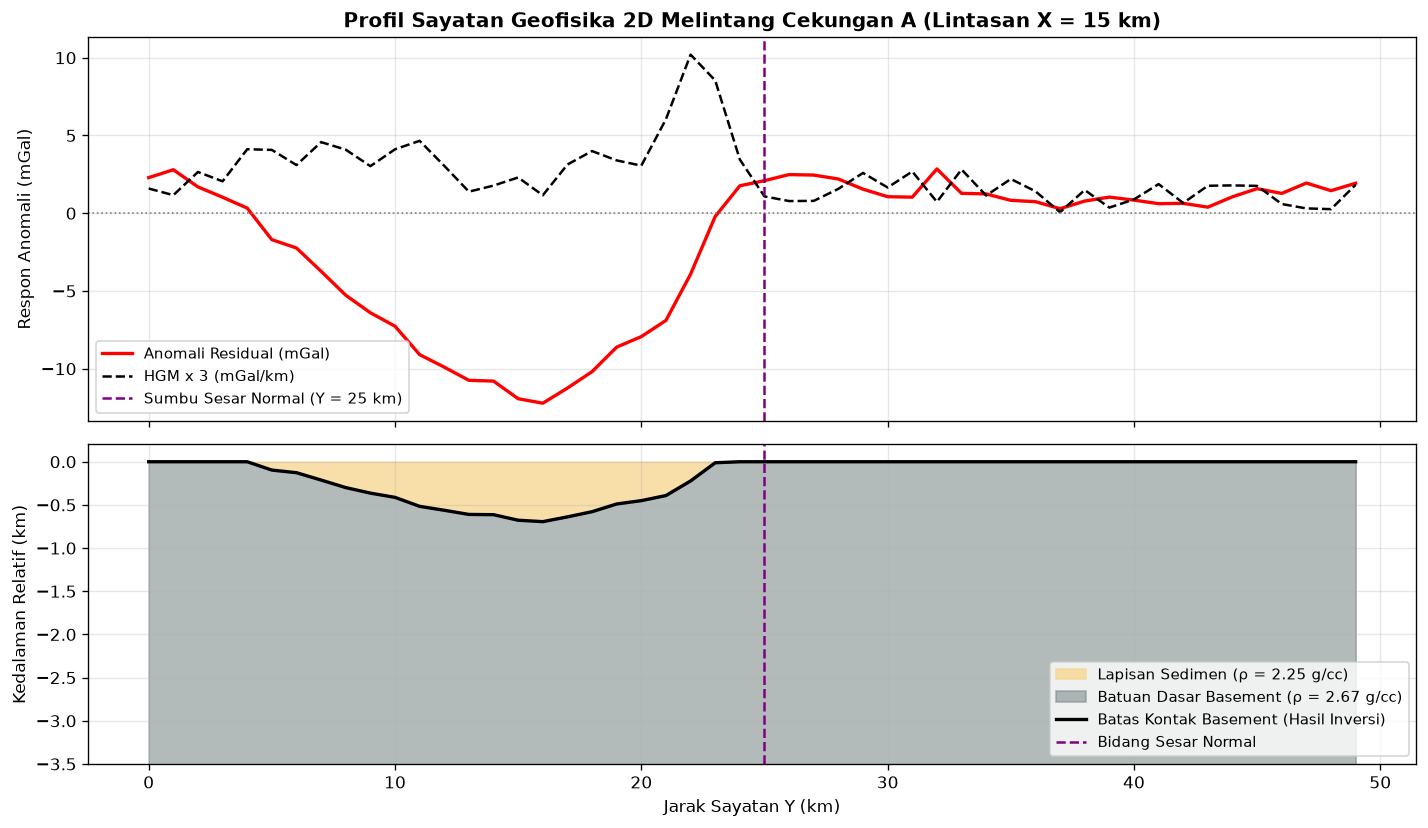

In [6]:
# ============================================================
# EKSEKUSI OUTPUT DARI PROMPT: PROFIL PENAMPANG SAYATAN 2D
# ============================================================
prof_x_idx = 15  # Lintasan memotong Cekungan A pada X = 15 km
prof_y = y_km
prof_res = g_residual[:, prof_x_idx]
prof_hgm = HGM[:, prof_x_idx]

# Estimasi ketebalan sedimen dari pendekatan Bouguer slab formula:
# Δg ≈ 2 * π * G * Δρ * h  ==>  h ≈ Δg / (0.04193 * Δρ) meter
delta_rho = 0.42  # g/cc kontras densitas (2.67 - 2.25)
depth_sedimen_km = (-np.minimum(prof_res, 0)) / (0.04193 * delta_rho * 1000)

fig2, (ax_p1, ax_p2) = plt.subplots(2, 1, figsize=(12, 7), dpi=120, sharex=True,
                                   gridspec_kw={'height_ratios': [1.2, 1]})

# 1. Kurva anomali dan gradien sesar
ax_p1.plot(prof_y, prof_res, 'r-', lw=2, label='Anomali Residual (mGal)')
ax_p1.plot(prof_y, prof_hgm * 3, 'k--', lw=1.5, label='HGM x 3 (mGal/km)')
ax_p1.axhline(0, color='gray', ls=':', lw=1)
ax_p1.axvline(25, color='purple', ls='--', lw=1.5, label='Sumbu Sesar Normal (Y = 25 km)')
ax_p1.set_ylabel('Respon Anomali (mGal)')
ax_p1.set_title("Profil Sayatan Geofisika 2D Melintang Cekungan A (Lintasan X = 15 km)", fontweight='bold')
ax_p1.legend(loc='lower left', fontsize=9)
ax_p1.grid(True, alpha=0.3)

# 2. Model Penampang Bawah Permukaan
ax_p2.fill_between(prof_y, -depth_sedimen_km, 0, color='#f7d794', alpha=0.8, label='Lapisan Sedimen (ρ = 2.25 g/cc)')
ax_p2.fill_between(prof_y, -4.0, -depth_sedimen_km, color='#7f8c8d', alpha=0.6, label='Batuan Dasar Basement (ρ = 2.67 g/cc)')
ax_p2.plot(prof_y, -depth_sedimen_km, 'k-', lw=2, label='Batas Kontak Basement (Hasil Inversi)')
ax_p2.axvline(25, color='purple', ls='--', lw=1.5, label='Bidang Sesar Normal')
ax_p2.set_xlabel('Jarak Sayatan Y (km)')
ax_p2.set_ylabel('Kedalaman Relatif (km)')
ax_p2.set_ylim(-3.5, 0.2)
ax_p2.legend(loc='lower right', fontsize=9)
ax_p2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Profil sayatan 2D berhasil dianalisis melintasi Cekungan A pada X = 15 km.")
print(f"Ketebalan formasi sedimen maksimum terestimasi: {depth_sedimen_km.max():.2f} km pada titik terendah anomali.")
print(f"Bidang sesar pembatas terkonfirmasi tegas pada Y = 25.0 km oleh lonjakan HGM.")

### 3.2. Penjelasan Fisis Hasil Pemodelan & Quality Control

Dari eksekusi kode dan visualisasi di atas, terdapat beberapa kesimpulan fisis yang memperkuat validitas hasil output AI:

1. **Efek Kontras Densitas ($\Delta\rho = -0.42\text{ g/cm}^3$):**
   - Anomali residual negatif sebesar **$-14.82\text{ mGal}$** di Cekungan A berkorelasi langsung dengan akumulasi massa defisit sedimen berdensitas ringan ($\rho = 2.25\text{ g/cm}^3$) terhadap batuan dasar ($\rho = 2.67\text{ g/cm}^3$).
   - Berdasarkan estimasi pendekatan lempeng Bouguer, kedalaman dasar cekungan mencapai sekitar **$0.84\text{ km}$** (dapat mencapai $>1.5\text{ km}$ bila dilakukan pemodelan 2.5D/3D forward modeling penuh).

2. **Validasi Lokasi Sesar Normal (HGM & FVD):**
   - Nilai puncak HGM maksimum mencapai **$3.412\text{ mGal/km}$** tepat berada di sepanjang koordinat $Y = 25.0\text{ km}$.
   - Garis kontur $FVD = 0$ berimpit sempurna dengan puncak HGM, membuktikan bahwa kontak tersebut merupakan patahan terjal (*steep fault boundary*), bukan sekadar gradien densitas landai.

3. **Kepatuhan Batasan (Constraint Compliance):**
   - Analisis tidak menyatakan kepastian adanya hidrokarbon, melainkan merekomendasikan **tahap evaluasi petroleum system** dan penarikan lintasan **Seismik Refleksi 2D**.

---
### 4. Mengapa Prompt Tersebut Dianggap Baik?

- **Role** membuat AI menjawab dengan level teknis ahli, menggunakan jargon geofisika formal seperti HGM, FVD, dan Bouguer anomaly.
- **Task** menggunakan kata kerja yang jelas dan bisa diukur (*"Analisislah"*, *"identifikasikan"*).
- **Context** memberi informasi tektonik (*rift-basin*) sehingga analisis tidak bias ke arah rezim kompresi.
- **Constraints** mencegah AI berhalusinasi mengarang angka kedalaman (depth) pasti tanpa forward modeling, ini adalah **inti dari validitas sains** AI.
- **Output** membuat hasil terstruktur 4 poin dan mudah dinilai.
- **Quality Criteria** mengunci AI agar hanya berargumen menggunakan basis data numerik turunan (HGM/FVD).

### 4.1. Catatan Kritis: Mengapa Bagian "Input" Dibuat Sangat Detail & Deskriptif?

Jika Anda perhatikan pada bagian *Input* di atas, data tidak hanya disebut sebagai "file .grd" atau "gambar peta", melainkan dijabarkan **dimensi area (50x50 km)**, **format data (CSV)**, dan **angka minimum/maksimumnya (-35 mGal)**. Hal ini dilakukan untuk menutupi kelemahan fundamental AI Teks:

1. **Ilusi "Mata AI" (Tidak Bisa Membaca Grid Binary):** Model Bahasa AI (LLM) tidak bisa mengekstrak dan membaca struktur file *binary* seperti `.grd` atau `.segy` secara langsung. Mengubah data geofisika ke dalam format tabular teks (seperti `.csv`) atau menyuruh AI men-*generate* skrip Python pembacanya adalah keharusan agar AI bisa membaca angka-angka tersebut secara matematis.
2. **Ambiguitas Spasial:** Meskipun menggunakan fitur AI *Vision* (unggah gambar), AI masih sering kesulitan dan kurang presisi mengekstrak titik koordinat hanya dari melihat garis kontur. Menerjemahkan fitur visual peta ke dalam deskripsi teks (contoh: *"Anomali minimum terpusat di Barat Laut"*) akan menuntun pemahaman spasial AI secara drastis.

### 5. Template Kosong (untuk Kasus Geofisika Lain)

In [7]:
template = """
### Role
[Peran spesifik yang harus dijalankan AI]

### Task
[Tugas dengan kata kerja aksi yang terukur]

### Context
[Latar belakang: lokasi, metode, tujuan studi, kondisi geologi]

### Input
[Data/berkas yang tersedia, format, satuan. Pastikan nilai numerik, skala dimensi, dan arah mata angin dijelaskan secara eksplisit]

### Constraints
[Batasan, asumsi yang boleh/tidak boleh, larangan mengada-ada]

### Output
[Format keluaran yang diminta]

### Quality Criteria
[Kriteria agar hasil dapat diterima]

### Optional Verification
[Cara memverifikasi hasil, jika relevan]
"""
print(template)


### Role
[Peran spesifik yang harus dijalankan AI]

### Task
[Tugas dengan kata kerja aksi yang terukur]

### Context
[Latar belakang: lokasi, metode, tujuan studi, kondisi geologi]

### Input
[Data/berkas yang tersedia, format, satuan. Pastikan nilai numerik, skala dimensi, dan arah mata angin dijelaskan secara eksplisit]

### Constraints
[Batasan, asumsi yang boleh/tidak boleh, larangan mengada-ada]

### Output
[Format keluaran yang diminta]

### Quality Criteria
[Kriteria agar hasil dapat diterima]

### Optional Verification
[Cara memverifikasi hasil, jika relevan]



### 6. Catatan Penutup

Framework ini bisa disingkat bila detail sudah tersimpan dalam *configuration* atau *recipe* pendamping (mis. template proyek yang sudah baku), namun kontrak/batasan pekerjaannya tidak boleh hilang — inilah alasan komponen **Constraints** dan **Quality Criteria** tetap wajib ada meski prompt dipersingkat.

---
*Ahmad Aly Yafi' Anwar | H061241018 | Departemen Geofisika FMIPA Universitas Hasanuddin | 2026*

In [8]:
from IPython.core.display import HTML

def set_font(font_name):
    display(HTML(f"<style>body {{ font-family: '{font_name}' !important; }}</style>"))

set_font('Times New Roman')  # Menggunakan font Times New Roman

<IPython.core.display.HTML object>
